In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import os
import pandas as pd
import datetime as dt
import matplotlib.colors as mcolors
import json
import csv
from itertools import product
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, Normalize
import seaborn as sns
import pandas as pd



In [2]:
class data():
    def __init__(self,folder,period,start_date, end_date,BG,BG_ds,footprint='spec001_mr',correlation='with',g_err=2,i_err=3):
        self.folder = folder
        self.period = period
        self.start_date=start_date
        self.end_date=end_date
        self.correlation=correlation
        self.color=''
        self.BG=BG
        self.BG_ds=BG_ds
        self.g_err=g_err
        self.i_err=i_err
        self.footprint=footprint
        self.path = f'{self.folder}/2x2/{self.correlation}_correlation/footprint_{self.footprint}/{self.g_err}ppm_gosat_meas_err/{self.i_err}ppm_insitu_meas_err/'
        
    # Class attributes
    def read_fluxes(self):
        self.fluxes=xr.open_dataset(f'{self.path}/{self.period}_{self.BG_ds}_bg.nc')
        self.fluxes['time']=pd.to_datetime(self.fluxes.time)
        self.fluxes=self.fluxes.where((self.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(self.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
    def read_gosat(self):
        self.gosat=xr.open_dataset(f'{self.path}/gosat_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.gosat=self.gosat.drop_dims(['time','latitude','longitude'])
        self.gosat=self.gosat.where((self.gosat.release_time>=pd.to_datetime(self.start_date))&(self.gosat.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.gosat=self.gosat.where((self.gosat.release_lat>analy_region_lat[0])&(self.gosat.release_lat<analy_region_lat[1])&(self.gosat.release_lon>analy_region_lon[0])&(self.gosat.release_lon<analy_region_lon[1]),drop=True)

    def read_insitu(self):
        self.insitu=xr.open_dataset(f'{self.path}/insitu_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.insitu=self.insitu.drop_dims(['time','latitude','longitude'])
        self.insitu=self.insitu.where((self.insitu.release_time>=pd.to_datetime(self.start_date))&(self.insitu.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.insitu=self.insitu.where((self.insitu.release_lat>analy_region_lat[0])&(self.insitu.release_lat<analy_region_lat[1])&(self.insitu.release_lon>analy_region_lon[0])&(self.insitu.release_lon<analy_region_lon[1]),drop=True)
    def read_tccon(self):
        self.tccon=xr.open_dataset(f'{self.path}/TCCON_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.tccon=self.tccon.drop_dims(['time','latitude','longitude'])
        self.tccon=self.tccon.where((self.tccon.release_time>=pd.to_datetime(self.start_date))&(self.tccon.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.tccon=self.tccon.where((self.tccon.release_lat>analy_region_lat[0])&(self.tccon.release_lat<analy_region_lat[1])&(self.tccon.release_lon>analy_region_lon[0])&(self.tccon.release_lon<analy_region_lon[1]),drop=True)

    def read_data(self):
        self.read_fluxes()
        self.read_gosat()
        self.read_insitu()
        self.read_tccon()

In [3]:
def plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors,markers, title, start_date, end_date,spath):
    ''' plot time series of prior, posterior and TM5-4DVar reference fluxes for all grid cells in inner domain
    Args:
        data_dir:   path to inversion directory
        ref_flux_dir: TM5-4DVar flux directory
        gosat_err_val: gosat measurement error value
        meas_err_val: insitu measurement error value
        corr_str: sting indicating if with or withour correlation
        color_sel: color for posterior flux
        bg_str: TM5-4DVar dataset used for the background, defaults to RemoTeC_2.4.0+IS
    Returns: nothing, saves plot'''
    data={}
    for k,dir in enumerate(datasets_dir):
        print(dir)
        data[labels[k]]=xr.open_dataset(dir).sel(latitude=slice(20,48), longitude=slice(-123,-73))

    title_str=f'Total 2x2 flux, {title}'
    lat_lon_list=[(lat, lon) for lat in data[labels[0]].latitude.values for lon in data[labels[0]].longitude.values]
    # sort by latitude descending, longitude ascending
    lat_lon_list=sorted(lat_lon_list, key=lambda x: (-x[0], x[1]))
    # plot overview
    fig, ax=plt.subplots(data[labels[0]].latitude.size, data[labels[0]].longitude.size, figsize=(data[labels[0]].longitude.size*6, data[labels[0]].latitude.size*6), sharey=True)
    ax=ax.flatten()
    # marker size
    ms=2
    for i in range(0, len(lat_lon_list)):
        lat_sel, lon_sel =lat_lon_list[i]
        # select region
        for k in range(len(labels)):
            if 'GCP' in labels[k]:
                s=labels[k][-1]
                data_sel=data[labels[k]].sel(ensemble_member=int(s))
                data_sel=data_sel.sel(latitude=lat_sel, longitude=lon_sel)
                name=''
                for r in data_sel.ensemble_member_name.values[0]:
                    name+=r
                ax[i].plot(data_sel.time, data_sel[parameters[k]], c=colors[k], marker=markers[k], markersize=ms, label=name)
            else:
                data_sel=data[labels[k]].sel(latitude=lat_sel, longitude=lon_sel)
                ax[i].plot(data_sel.time, data_sel[parameters[k]], c=colors[k], marker=markers[k], markersize=ms, label=labels[k])
            if parameters_uncertainty[k]!=False:
                ax[i].fill_between(data_sel.time, data_sel[parameters[k]]-data_sel[parameters_uncertainty[k]], data_sel[parameters[k]]+data_sel[parameters_uncertainty[k]], 
                                color=colors[k], alpha=0.2)        
        ax[i].legend()
        ax[i].set_title(f'lat/lon: {lat_sel}/{lon_sel}')
        ax[i].set_xlim(start_date,end_date)
        #ax[i].set_xlim(dt.date(2010,1,1), dt.date(2010,12,31))
        ax[i].tick_params(labelleft=True)
        ax[i].set_ylim(-4e-7, 4e-7)
        # You can change the step of range() as you prefer (now, it selects each third month) 
        ax[i].xaxis.set_major_locator(mdates.MonthLocator(bymonth=range(1,12,3)))
        ax[i].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=range(1,13,1)))
        ax[i].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax[i].grid(which='both', c='grey', alpha=0.5)
    fig.suptitle(title_str)
    fig.tight_layout(rect=[0, 0., 1, 0.98])

    fig.savefig(spath)
    print(f'saved to: {spath}')
    plt.close()
    return

In [4]:
def plot_inner_2x2_region_fluxes_from_datasets(datasets,labels, colors,markers, title, start_date, end_date,spath,min_max=(-4e-7,4e-7)):
    ''' plot time series of prior, posterior and TM5-4DVar reference fluxes for all grid cells in inner domain
    Args:
        data_dir:   path to inversion directory
        ref_flux_dir: TM5-4DVar flux directory
        gosat_err_val: gosat measurement error value
        meas_err_val: insitu measurement error value
        corr_str: sting indicating if with or withour correlation
        color_sel: color for posterior flux
        bg_str: TM5-4DVar dataset used for the background, defaults to RemoTeC_2.4.0+IS
    Returns: nothing, saves plot'''
    data={}
    for k,dataset in enumerate(datasets):
        print(dir)
        data[labels[k]]=dataset.sel(latitude=slice(20,48), longitude=slice(-123,-73))

    title_str=f'2x2 flux {title}'
    lat_lon_list=[(lat, lon) for lat in data[labels[0]].latitude.values for lon in data[labels[0]].longitude.values]
    # sort by latitude descending, longitude ascending
    lat_lon_list=sorted(lat_lon_list, key=lambda x: (-x[0], x[1]))
    # plot overview
    fig, ax=plt.subplots(data[labels[0]].latitude.size, data[labels[0]].longitude.size, figsize=(data[labels[0]].longitude.size*6, data[labels[0]].latitude.size*6), sharey=True)
    ax=ax.flatten()
    # marker size
    ms=2
    for i in range(0, len(lat_lon_list)):
        lat_sel, lon_sel =lat_lon_list[i]
        # select region
        for k in range(len(labels)):
            data_sel=data[labels[k]].sel(latitude=lat_sel, longitude=lon_sel)
            ax[i].plot(data_sel.time, data_sel, c=colors[k], marker=markers[k], markersize=ms, label=labels[k])      
        ax[i].legend(ncol=3)
        ax[i].set_title(f'lat/lon: {lat_sel}/{lon_sel}')
        ax[i].set_xlim(start_date,end_date)
        #ax[i].set_xlim(dt.date(2010,1,1), dt.date(2010,12,31))
        ax[i].tick_params(labelleft=True)
        ax[i].set_ylim(min_max[0],min_max[1])
        # You can change the step of range() as you prefer (now, it selects each third month) 
        ax[i].xaxis.set_major_locator(mdates.MonthLocator(bymonth=range(1,12,3)))
        ax[i].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=range(1,13,1)))
        ax[i].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax[i].grid(which='both', c='grey', alpha=0.5)
    fig.suptitle(title_str)
    fig.tight_layout(rect=[0, 0., 1, 0.98])

    fig.savefig(spath)
    print(f'saved to: {spath}')
    plt.close()
    return

In [5]:
def plot_map(data,label,ax,vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax,rasterized=True, cbar_kwargs={'location':'bottom','shrink':0.85, 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(12)
    plot.colorbar.ax.tick_params(labelsize=12)
        
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='g')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='g')
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [6]:
def plot_map_divided(data,label,ax,vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax, cbar_kwargs={'location':'bottom','shrink':0.85, 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(12)
    plot.colorbar.ax.tick_params(labelsize=12)
    for i in range(n_regions[0]): #lat
        for j in range(n_regions[1]): #lon
            ax.hlines(regions_lat[i],regions_lon[j], regions_lon[j+1],color='b')
            ax.vlines(regions_lon[j],regions_lat[i],regions_lat[i+1],color='b')
        
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='g')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='g')
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [7]:
def get_start_date_of_week(date):
    ''' Get monday date of the of the week containing the given date
    Args: date
    Returns: date of monday in corresponding week'''
    start_date=date-dt.timedelta(days=date.weekday())   # dt.date().weekday() goes from 0 to 6
    return start_date

In [8]:
analy_region_lat=[20,48]
analy_region_lon=[-126,-70]

# four_times_four 
res=2
n_regions=[3,4] #lat, lon
lat_dist=round((analy_region_lat[1]-analy_region_lat[0])/n_regions[0]/res)*res
lon_dist=round((analy_region_lon[1]-analy_region_lon[0])/n_regions[1]/res)*res
#define region edges
regions_lat=[]
for i in range(n_regions[0]+1): #lat
    if i == n_regions[0]:
        regions_lat.append(analy_region_lat[1])
    else:
        regions_lat.append(analy_region_lat[0]+i*lat_dist)
regions_lon=[]
for i in range(n_regions[1]+1): #lat
    if i == n_regions[1]:
        regions_lon.append(analy_region_lon[1])
    else:
        regions_lon.append(analy_region_lon[0]+i*lon_dist)

In [9]:
print(regions_lat)
print(regions_lon)

[20, 30, 40, 48]
[-126, -112, -98, -84, -70]


In [10]:
period='20191001-20230331'
analysis_start_date, analysis_end_date =dt.date(2020,1,1), dt.date(2022,12,31)  
start_date, end_date =dt.date(2019,10,1), dt.date(2023,3,31)  
color=['red','blue','yellow','purple','gray','orange', 'pink']
savefig='figures_2/3years/analyse_different_models/4x3'

In [11]:
seasons={
    'Winter': [12,1,2],
    'Spring': [3,4,5],
    'Summer': [6,7,8],
    'Autumn': [9.,10,11]
}

In [12]:
path='inversions_new/TM5_3_years/'
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'

inversion=data(path,period,start_date, end_date,BG,BG_ds,footprint='spec001_mr',correlation='with',g_err=2,i_err=3)
inversion.read_data()

In [13]:
TM54DVar_posterior_flux=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc')
TM54DVar_posterior_flux=TM54DVar_posterior_flux.where((TM54DVar_posterior_flux.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(TM54DVar_posterior_flux.time<=pd.to_datetime(analysis_end_date)),drop=True)

In [14]:
prior=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_prior_cut_weekly.nc')
prior=prior.where((prior.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(prior.time<=pd.to_datetime(analysis_end_date)),drop=True)

In [15]:
GCP=xr.open_dataset('/work/bb1170/RUN/b383736/data/GCP/GCP2024_inversions_2x2_version1_2_20241021_cut_weekly.nc')
GCP=GCP.where((GCP.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(GCP.time<=pd.to_datetime(analysis_end_date)),drop=True)
gcp_names=[]
for i in GCP.ensemble_member:
    gcp_names.append(GCP.sel(ensemble_member=i).ensemble_member_name.values[0].sum())
print(gcp_names)


['CarboScope', 'CAMS', 'CTE', 'NISMON-CO2', 'CT-NOAA', 'CMS-Flux', 'CAMS-Satellite', 'GONGGA', 'COLA', 'GCASv2', 'UoE', 'IAPCAS', 'MIROC', 'NTFVAR']


## total flux comparison

In [16]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(32,25))
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for i in range(n_regions[0]): #lat(0.02, plt.cm.Reds(0.60)),
    for j in range(n_regions[1]): #lon
        for ensemble in (GCP.ensemble_member.values):
            temp=GCP.sel(ensemble_member=ensemble)
            temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            color=(ensemble+8)/(len(GCP.ensemble_member)+10)
            axs[i,j].plot(temp.time, temp.total_flux*1e6, marker='o', color= plt.cm.Greens(color), markersize=2,label=gcp_names[ensemble])
        temp=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])    
        axs[i,j].plot(temp.time, temp.total_flux*1e6, marker='o', color=default_colors[1], markersize=2,label='TM5-4DVar')
        temp=inversion.fluxes.where(((inversion.fluxes.latitude>= regions_lat[-i-2]) &(inversion.fluxes.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.TM5_prior_flux*1e6, marker='o', color='black', markersize=2,label='prior')
        #axs[i,j].fill_between(temp.time, temp.TM5_prior_flux*1e6-temp.prior_uncertainty*1e6, temp.TM5_prior_flux*1e6+temp.prior_uncertainty*1e6, color='black', alpha=0.2) 
        axs[i,j].plot(temp.time, temp.TM5_posterior_flux*1e6, marker='o', color=default_colors[0], markersize=2,label='our posterior')
        axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux*1e6-temp.TM5_posterior_std*1e6, temp.TM5_posterior_flux*1e6+temp.TM5_posterior_std*1e6, color=default_colors[0], alpha=0.2) 
        if j==0:
            axs[i,j].set_ylabel('Total CO2 Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=24)
            axs[i,j].tick_params(labelsize =20)
        else:
            axs[i,j].tick_params(labelleft=False)
        axs[i,j].set_ylim(-0.3,0.15)
        axs[i,j].set_xlim(analysis_start_date,analysis_end_date)
        if (i==2)&(j==0):
            axs[i,j].legend(ncol=2,loc='lower left',fontsize=18)
        if i==2:
            axs[i,j].tick_params(axis='x', labelrotation=90,labelsize =20)
            #axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)  
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)                 
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E", fontsize=24)
               
plt.tight_layout()
plt.savefig(f'{savefig}/total_flux_regional_timeline.pdf',bbox_inches='tight')#,transparent=True)
#plt.show()
plt.close()
    

In [ ]:
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for ensemble in (GCP.ensemble_member.values):
    fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
    for i in range(n_regions[0]): #lat(0.02, plt.cm.Reds(0.60)),
        for j in range(n_regions[1]): #lon
            temp=inversion.fluxes.where(((inversion.fluxes.latitude>= regions_lat[-i-2]) &(inversion.fluxes.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            axs[i,j].plot(temp.time, temp.TM5_posterior_flux*1e6, marker='o', color=default_colors[0], markersize=2,label='our model posterior')
            axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux*1e6-temp.TM5_posterior_std*1e6, temp.TM5_posterior_flux*1e6+temp.TM5_posterior_std*1e6, color=default_colors[0], alpha=0.2) 
            
            axs[i,j].plot(temp.time, temp.TM5_prior_flux*1e6, marker='o', color=default_colors[1], markersize=2,label='prior')
            #axs[i,j].fill_between(temp.time, temp.TM5_prior_flux*1e6-temp.prior_uncertainty*1e6, temp.TM5_prior_flux*1e6+temp.prior_uncertainty*1e6, color='black', alpha=0.2) 

            temp=GCP.sel(ensemble_member=ensemble)
            temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            color=(ensemble+1)/(len(GCP.ensemble_member)+5)
            axs[i,j].plot(temp.time, temp.total_flux*1e6, marker='o', color= plt.cm.Greens(color), markersize=2,label=gcp_names[ensemble])

            axs[i,j].set_ylabel('total co2 flux [[$\\mathrm{\\frac{mgCO_2}{s m^2}}$]]')
            axs[i,j].set_ylim(-0.2,0.15)
            axs[i,j].legend()
            axs[i,j].tick_params(axis='x', labelrotation=45)

            axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
                
    plt.tight_layout()
    plt.savefig(f'{savefig}/total_flux_regional_timeline_{gcp_names[ensemble]}.png',bbox_inches='tight')#,transparent=True)
    #plt.show()
    plt.close()

In [20]:
GCP

<xarray.Dataset> Size: 88MB
Dimensions:                                (time: 157, ensemble_member: 14,
                                            nchars: 20, latitude: 22,
                                            longitude: 36)
Coordinates:
  * time                                   (time) datetime64[ns] 1kB 2019-12-...
  * latitude                               (latitude) float32 88B 13.0 ... 55.0
  * longitude                              (longitude) float32 144B -133.0 .....
Dimensions without coordinates: ensemble_member, nchars
Data variables:
    ensemble_member_name                   (time, ensemble_member, nchars) object 352kB ...
    cell_area                              (time, latitude, longitude) float64 995kB ...
    land_flux_only_fossil_cement_adjusted  (time, ensemble_member, latitude, longitude) float64 14MB ...
    ocean_flux_NOT_adjusted                (time, ensemble_member, latitude, longitude) float64 14MB ...
    prior_flux_land                        (time, ensemble_member, latitude, longitude) float64 14MB ...
    prior_flux_ocean                       (time, ensemble_member, latitude, longitude) float64 14MB ...
    fossil_fuel_emissions                  (time, ensemble_member, latitude, longitude) float64 14MB ...
    river_adjustment_land                  (time, latitude, longitude) float64 995kB ...
    river_adjustment_land_scaled           (time, latitude, longitude) float64 995kB ...
    river_adjustment_ocean                 (time, latitude, longitude) float64 995kB ...
    total_flux                             (time, ensemble_member, latitude, longitude) float64 14MB ...
Attributes: (12/18)
    contact:                    Ingrid Luijkx, Wageningen University, ingrid....
    contact_all:                Comma separated email addresses: christian.ro...
    Conventions:                CF-1.8
    creation_date:              2024-10-21
    creator:                    Ingrid Luijkx, Wageningen University, orcid:0...
    crs:                        spherical earth with radius of 6371 km
    ...                         ...
    product_version:            1.0
    project:                    Global Carbon Project, GCB2024
    references:                 Please inform the inverse modelling group whe...
    source:                     Below is a list of the versions of each syste...
    summary:                    In this file, we include the data from the GC...
    title:                      Global CO2 gridded flux fields from 14 atmosp...

In [24]:
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
datasets=[prior.total_flux,TM54DVar_posterior_flux.total_flux,inversion.fluxes.TM5_posterior_flux]
labels=['prior','TM5-4DVar', 'our posterior' ]
colors=['black','grey',default_colors[0]]
marker=['x','x','o']

for k in range(len(GCP.ensemble_member)):
    datasets.append(GCP.sel(ensemble_member=k).total_flux)
    color=(k+1)/(len(GCP.ensemble_member)+5)
    labels.append(gcp_names[k])
    colors.append( plt.cm.Greens(color))
    marker.append('x')
        

print(colors)
print(marker)
plot_inner_2x2_region_fluxes_from_datasets(datasets,labels, colors, marker,'different models', analysis_start_date, analysis_end_date,savefig+'/different_models_total_flux'+'2x2.png',min_max=(-4e-7, 4e-7))


['black', 'grey', '#1f77b4', (np.float64(0.9398385236447521), np.float64(0.977039600153787), np.float64(0.92719723183391), np.float64(1.0)), (np.float64(0.9110495963091119), np.float64(0.965843906189927), np.float64(0.8936101499423299), np.float64(1.0)), (np.float64(0.8680507497116494), np.float64(0.9487889273356401), np.float64(0.8464436755094195), np.float64(1.0)), (np.float64(0.8200692041522492), np.float64(0.9295963091118801), np.float64(0.7952633602460593), np.float64(1.0)), (np.float64(0.7651980007689351), np.float64(0.9073279507881584), np.float64(0.7381468665897731), np.float64(1.0)), (np.float64(0.7044213763936947), np.float64(0.8817377931564783), np.float64(0.6789696270665129), np.float64(1.0)), (np.float64(0.6389696270665128), np.float64(0.8541791618608228), np.float64(0.6152402921953095), np.float64(1.0)), (np.float64(0.568396770472895), np.float64(0.8215916955017301), np.float64(0.5560630526720491), np.float64(1.0)), (np.float64(0.4908881199538639), np.float64(0.7854209919

In [25]:
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
datasets=[prior.total_flux,TM54DVar_posterior_flux.total_flux,inversion.fluxes.TM5_posterior_flux]
labels=['prior','TM5-4DVar', 'our posterior' ]
colors=['black','grey',default_colors[0]]
marker=['x','x','o']
        

print(colors)
print(marker)
plot_inner_2x2_region_fluxes_from_datasets(datasets,labels, colors, marker,'different models', analysis_start_date, analysis_end_date,savefig+'/our_TM5_total_flux'+'2x2.png',min_max=(-4e-7, 4e-7))


['black', 'grey', '#1f77b4']
['x', 'x', 'o']
<built-in function dir>
<built-in function dir>
<built-in function dir>
saved to: figures_2/3years/analyse_different_models/4x3/our_TM5_total_flux2x2.png


In [22]:
for k in range(len(GCP.ensemble_member)):
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    datasets=[prior.total_flux,TM54DVar_posterior_flux.total_flux,inversion.fluxes.TM5_posterior_flux]
    labels=['prior','TM5-4DVar', 'our posterior' ]
    colors=['black','grey',default_colors[0]]
    marker=['x','x','o']

    datasets.append(GCP.sel(ensemble_member=k).total_flux)
    color=(k+1)/(len(GCP.ensemble_member)+5)
    labels.append(gcp_names[k])
    colors.append( 'green')
    marker.append('x')      

    print(colors)
    print(marker)
    plot_inner_2x2_region_fluxes_from_datasets(datasets,labels, colors, marker,'different models', analysis_start_date, analysis_end_date,savefig+f'/different_models_total_flux_{GCP.sel(ensemble_member=k).ensemble_member_name.values[0].sum()}'+'2x2.png',min_max=(-4e-7, 4e-7))

['black', 'grey', '#1f77b4', (np.float64(0.9398385236447521), np.float64(0.977039600153787), np.float64(0.92719723183391), np.float64(1.0))]
['x', 'x', 'o', 'x']
<built-in function dir>
<built-in function dir>
<built-in function dir>
<built-in function dir>
saved to: figures_2/3years/analyse_different_models/4x3/different_models_total_flux_CarboScope2x2.png
['black', 'grey', '#1f77b4', (np.float64(0.9110495963091119), np.float64(0.965843906189927), np.float64(0.8936101499423299), np.float64(1.0))]
['x', 'x', 'o', 'x']
<built-in function dir>
<built-in function dir>
<built-in function dir>
<built-in function dir>


In [27]:
savefig

'figures_2/3years/analyse_different_models/4x3'

To create the movie run in the terminal in the correct folder \
ffmpeg -framerate 1 -i frames/frame_%03d.png -c:v libx264 -pix_fmt yuv420p posterior_flux.mp4

In [18]:
k=0
for week in inversion.fluxes.time.values:
    fig,axs=plt.subplots(1,1,figsize=(7,6), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.text(0.5, 0.92, f"Week of the {str(np.datetime64(week,'D'))}", ha='center', fontsize=12, style='italic')
    #fig.subplots_adjust(right=0.85)

    temp=(inversion.fluxes.TM5_posterior_flux).sel(time=week)
    plot_map(temp*1e6,'our inversion total co2 flux [[$\\mathrm{\\frac{mgCO_2}{s m^2}}$]]',axs,vmin=-0.4,vmax=0.4)
    plt.savefig(f'{savefig}/frames/frame_{k:03d}.png')
    plt.close()
    k+=1


In [34]:
savefig

'figures_2/3years/analyse_different_models/4x3'

In [18]:
def plot_map_analysis(data,label,ax,vmin=-0.6,vmax=0.6):
    temp=data.where((data.latitude>=analy_region_lat[0])&(data.latitude<=analy_region_lat[1]),drop=True)
    temp=temp.where((temp.longitude>=analy_region_lon[0])&(temp.longitude<=analy_region_lon[1]),drop=True)
    plot=temp.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax,add_colorbar=False) 
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}
    ax.grid(c='lightgrey')
    ax.set_xlim(analy_region_lon[0],analy_region_lon[1]) 
    ax.set_ylim(analy_region_lat[0],analy_region_lat[1])
    ax.tick_params(labelsize=20)
    ax.set_title(label)
    ax.set_aspect(aspect=1)
    return plot


In [19]:
vmin,vmax=-0.2,0.2
import matplotlib.gridspec as gridspec

fig,axs=plt.subplots(6,3,figsize=(10,12), subplot_kw={'projection': ccrs.PlateCarree()})


temp=(inversion.fluxes.TM5_posterior_flux).mean('time')
plot=plot_map_analysis(temp*1e6,'our posterior',axs[0][0],vmin=vmin,vmax=vmax)
temp=(inversion.fluxes.TM5_prior_flux).mean('time')
plot=plot_map_analysis(temp*1e6,'Prior ',axs[0,2],vmin=vmin,vmax=vmax)
temp=(TM54DVar_posterior_flux.total_flux).mean('time')
plot=plot_map_analysis(temp*1e6,'TM5-4DVar',axs[0][1],vmin=vmin,vmax=vmax)
k=0
m=1
for l in range(len(GCP.ensemble_member.values)):
    temp=GCP.sel(ensemble_member=l).mean('time')
    plot=plot_map_analysis(temp.total_flux*1e6,f'{GCP.sel(ensemble_member=l).ensemble_member_name.values[0].sum()}',axs[m][k],vmin=vmin,vmax=vmax)
    k+=1 
    if k==3:
        m+=1
        k=0
# Reserve room on the right
fig.subplots_adjust(right=0.87)
# [left, bottom, width, height] in figure coordinates
cbar_ax = fig.add_axes([1.0, 0.15, 0.012, 0.70])

cbar = fig.colorbar(plot, cax=cbar_ax)
cbar.set_label('Total CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]', fontsize=12)
fig.delaxes(axs[5][2])

plt.tight_layout()
plt.savefig(savefig+'/maps/map_different_models_mean.pdf', bbox_inches='tight')
plt.close()


/tmp/ipykernel_2870489/2620310462.py:31: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


In [26]:
savefig

'figures_2/3years/analyse_different_models/4x3'

In [23]:
vmin,vmax=-0.2,0.2
for year in [2020,2021,2022]:
    fig,axs=plt.subplots(6,3,figsize=(10,12), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.text(0.52, 0.98, year, ha='center', fontsize=15)

    temp=(inversion.fluxes.TM5_posterior_flux)
    temp=temp.where(temp.time.dt.year==year,drop=True).mean('time')
    plot=plot_map_analysis(temp*1e6,'our inversion',axs[0,0],vmin=vmin,vmax=vmax)
    temp=(inversion.fluxes.TM5_prior_flux)
    temp=temp.where(temp.time.dt.year==year,drop=True).mean('time')
    plot=plot_map_analysis(temp*1e6,'Prior ',axs[0,2],vmin=vmin,vmax=vmax)
    temp=(TM54DVar_posterior_flux.total_flux)
    temp=temp.where(temp.time.dt.year==year,drop=True).mean('time')
    plot=plot_map_analysis(temp*1e6,'TM5-4DVar',axs[0,1],vmin=vmin,vmax=vmax)
    k=0
    m=1
    for l in range(len(GCP.ensemble_member.values)):
        temp=GCP.sel(ensemble_member=l)
        temp=temp.where(temp.time.dt.year==year,drop=True).mean('time')
        plot=plot_map_analysis(temp.total_flux*1e6,f'{GCP.sel(ensemble_member=l).ensemble_member_name.values[0].sum()}',axs[m][k],vmin=vmin,vmax=vmax)
        k+=1 
        if k==3:
            m+=1
            k=0
    # Reserve room on the right
    fig.subplots_adjust(right=0.87, top=1.5)
    # [left, bottom, width, height] in figure coordinates
    cbar_ax = fig.add_axes([1.0, 0.15, 0.012, 0.70])

    cbar = fig.colorbar(plot, cax=cbar_ax)
    cbar.set_label('Total CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]', fontsize=12)
    fig.delaxes(axs[5][2])

    plt.tight_layout()
    plt.savefig(savefig+f'/maps/map_different_models_{year}.pdf', bbox_inches='tight')
    #plt.show()
    plt.close()


/tmp/ipykernel_1494463/2543877113.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_1494463/2543877113.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_1494463/2543877113.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


In [25]:
for season in seasons:
    print(season)
    vmin,vmax=-0.2,0.2
    fig,axs=plt.subplots(6,3,figsize=(10,12), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.text(0.52, 0.98, f"Mean {season}", ha='center', fontsize=15, style='italic')
    
    temp=(inversion.fluxes.TM5_posterior_flux)
    temp=temp.where((temp.time.dt.month == seasons[season][0])|(temp.time.dt.month == seasons[season][0])|(temp.time.dt.month == seasons[season][0]),drop=True)
    temp=temp.mean('time')
    plot=plot_map_analysis(temp*1e6,'our inversion',axs[0,0],vmin=vmin,vmax=vmax)
    temp=(inversion.fluxes.TM5_prior_flux)
    temp=temp.where((temp.time.dt.month == seasons[season][0])|(temp.time.dt.month == seasons[season][0])|(temp.time.dt.month == seasons[season][0]),drop=True)
    temp=temp.mean('time')
    plot=plot_map_analysis(temp*1e6,'Prior ',axs[0,2],vmin=vmin,vmax=vmax)
    temp=(TM54DVar_posterior_flux.total_flux)
    temp=temp.where((temp.time.dt.month == seasons[season][0])|(temp.time.dt.month == seasons[season][0])|(temp.time.dt.month == seasons[season][0]),drop=True)
    temp=temp.mean('time')
    plot=plot_map_analysis(temp*1e6,'TM5-4DVar',axs[0,1],vmin=vmin,vmax=vmax)
    k=0
    m=1
    for l in range(len(GCP.ensemble_member.values)):
        temp=GCP.sel(ensemble_member=l)
        temp=temp.where((temp.time.dt.month == seasons[season][0])|(temp.time.dt.month == seasons[season][0])|(temp.time.dt.month == seasons[season][0]),drop=True)
        temp=temp.mean('time')
        plot=plot_map_analysis(temp.total_flux*1e6,f'{GCP.sel(ensemble_member=l).ensemble_member_name.values[0].sum()}',axs[m,k],vmin=vmin,vmax=vmax)
        k+=1 
        if k==3:
            m+=1
            k=0
    # Reserve room on the right
    fig.subplots_adjust(right=0.87, top=1.5)
    # [left, bottom, width, height] in figure coordinates
    cbar_ax = fig.add_axes([1.0, 0.15, 0.012, 0.70])

    cbar = fig.colorbar(plot, cax=cbar_ax)
    cbar.set_label('Total CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]', fontsize=12)
    fig.delaxes(axs[5][2])
    plt.tight_layout()
    plt.savefig(savefig+f'/maps/map_different_models_mean_{season}.pdf',bbox_inches='tight')
    plt.close()



Winter


/tmp/ipykernel_1494463/896904147.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Spring


/tmp/ipykernel_1494463/896904147.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Summer


/tmp/ipykernel_1494463/896904147.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Autumn


/tmp/ipykernel_1494463/896904147.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


### individual seasons

In [20]:
season=''
dates=[]
temp_inv=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
for week in temp_inv.time.values:
    if season != [season for season in seasons if int(week.astype('datetime64[M]').astype(int) % 12 + 1) in seasons[season]][0]:
        if season !='':
            vmin,vmax=-0.2,0.2
            fig,axs=plt.subplots(4,4,figsize=(16,10), subplot_kw={'projection': ccrs.PlateCarree()})
            #fig.suptitle(f"mean {season}", fontsize=12, style='italic')
            fig.text(0.5, 0.92, f"{season}: {str(dates[0])[:7]}_{str(dates[-1])[:7]}", ha='center', fontsize=15, style='italic')
            temp=(inversion.fluxes.TM5_posterior_flux)
            temp=temp.sel(time=dates).mean('time')            
            plot=plot_map_analysis(temp*1e6,'our inversion',axs[0,0],vmin=vmin,vmax=vmax)
            #plot_map(temp*1e6,'prior total co2 flux [[$\\mathrm{\\frac{mgCO_2}{s m^2}}$]]',axs[0,1],vmin=-0.4,vmax=0.4)
            temp=(TM54DVar_posterior_flux.total_flux)
            temp=temp.sel(time=dates).mean('time') 
            plot=plot_map_analysis(temp*1e6,'TM5-4DVar',axs[0,1],vmin=vmin,vmax=vmax)
            k=2
            m=0
            for l in range(len(GCP.ensemble_member.values)):
                temp=GCP.sel(ensemble_member=l)
                temp=temp.sel(time=dates).mean('time') 
                plot=plot_map_analysis(temp.total_flux*1e6,f'{GCP.sel(ensemble_member=l).ensemble_member_name.values[0].sum()}',axs[m,k],vmin=vmin,vmax=vmax)
                k+=1 
                if k==4:
                    m+=1
                    k=0
            # Reserve room on the right
            fig.subplots_adjust(right=0.87)
            # [left, bottom, width, height] in figure coordinates
            cbar_ax = fig.add_axes([0.9, 0.15, 0.012, 0.70])

            cbar = fig.colorbar(plot, cax=cbar_ax)
            cbar.set_label('total $CO_2$ flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]', fontsize=12)

            plt.savefig(savefig+f'/maps/map_different_models_{season}_{str(dates[0])[:7]}_{str(dates[-1])[:7]}.png')
            plt.close()

        season=[season for season in seasons if int(week.astype('datetime64[M]').astype(int) % 12 + 1) in seasons[season]][0]
        dates=[week]
    else:
        dates.append(week)
        continue


In [17]:
temp_inv=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)


In [22]:
temp_inv.where((temp_inv.time.dt.year==2021)&(temp_inv.time.dt.month==10),drop=True).time.values

array(['2021-10-04T00:00:00.000000000', '2021-10-11T00:00:00.000000000',
       '2021-10-18T00:00:00.000000000', '2021-10-25T00:00:00.000000000'],
      dtype='datetime64[ns]')

In [19]:
temp_inv=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
vmin,vmax=-0.2,0.2
for year in [2020,2021,2022]:
    dates=temp_inv.where((temp_inv.time.dt.year==year)&(temp_inv.time.dt.month==10),drop=True).time.values
    fig,axs=plt.subplots(4,4,figsize=(16,10), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"Posterior", fontsize=12, style='italic')
    fig.text(0.5, 0.92, f"Oktober {year}", ha='center', fontsize=15, style='italic')
    temp=(inversion.fluxes.TM5_posterior_flux)
    temp=temp.sel(time=dates).mean('time')            
    plot=plot_map_analysis(temp*1e6,'our inversion',axs[0,0],vmin=vmin,vmax=vmax)
    #plot_map(temp*1e6,'prior total co2 flux [[$\\mathrm{\\frac{mgCO_2}{s m^2}}$]]',axs[0,1],vmin=-0.4,vmax=0.4)
    temp=(TM54DVar_posterior_flux.total_flux)
    temp=temp.sel(time=dates).mean('time') 
    plot=plot_map_analysis(temp*1e6,'TM5-4DVar',axs[0,1],vmin=vmin,vmax=vmax)
    k=2
    m=0
    for l in range(len(GCP.ensemble_member.values)):
        temp=GCP.sel(ensemble_member=l)
        temp=temp.sel(time=dates).mean('time') 
        plot=plot_map_analysis(temp.total_flux*1e6,f'{GCP.sel(ensemble_member=l).ensemble_member_name.values[0].sum()}',axs[m,k],vmin=vmin,vmax=vmax)
        k+=1 
        if k==4:
            m+=1
            k=0
    # Reserve room on the right
    fig.subplots_adjust(right=0.87)
    # [left, bottom, width, height] in figure coordinates
    cbar_ax = fig.add_axes([0.9, 0.15, 0.012, 0.70])

    cbar = fig.colorbar(plot, cax=cbar_ax)
    cbar.set_label('total $CO_2$ flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]', fontsize=12)

    plt.savefig(savefig+f'/maps/map_different_models_Oktober_{year}.png')
    plt.close()



In [20]:
temp_inv=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
vmin,vmax=-0.2,0.2
for year in [2020,2021,2022]:
    dates=temp_inv.where((temp_inv.time.dt.year==year)&(temp_inv.time.dt.month==10),drop=True).time.values
    fig,axs=plt.subplots(4,4,figsize=(16,10), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"posterior - prior", fontsize=12, style='italic')
    fig.text(0.5, 0.92, f"Oktober {year}", ha='center', fontsize=15, style='italic')
    temp=(inversion.fluxes.TM5_posterior_flux-inversion.fluxes.TM5_prior_flux)
    temp=temp.sel(time=dates).mean('time')            
    plot=plot_map_analysis(temp*1e6,'our inversion',axs[0,0],vmin=vmin,vmax=vmax)
    #plot_map(temp*1e6,'prior total co2 flux [[$\\mathrm{\\frac{mgCO_2}{s m^2}}$]]',axs[0,1],vmin=-0.4,vmax=0.4)
    temp=(TM54DVar_posterior_flux.total_flux-prior.total_flux)
    temp=temp.sel(time=dates).mean('time') 
    plot=plot_map_analysis(temp*1e6,'TM5-4DVar',axs[0,1],vmin=vmin,vmax=vmax)
    k=2
    m=0
    for l in range(len(GCP.ensemble_member.values)):
        temp=GCP.sel(ensemble_member=l)
        temp=temp.sel(time=dates).mean('time') 
        plot=plot_map_analysis((temp.total_flux-temp.prior_total)*1e6,f'{GCP.sel(ensemble_member=l).ensemble_member_name.values[0].sum()}',axs[m,k],vmin=vmin,vmax=vmax)
        k+=1 
        if k==4:
            m+=1
            k=0
    # Reserve room on the right
    fig.subplots_adjust(right=0.87)
    # [left, bottom, width, height] in figure coordinates
    cbar_ax = fig.add_axes([0.9, 0.15, 0.012, 0.70])

    cbar = fig.colorbar(plot, cax=cbar_ax)
    cbar.set_label('total $CO_2$ flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]', fontsize=12)

    plt.savefig(savefig+f'/maps/map_different_models_Oktober_{year}_minus_prior.png')
    plt.close()



### prior

In [22]:
GCP['prior_total']=GCP.prior_flux_land+GCP.prior_flux_ocean#+GCP.fossil_fuel_emissions

In [23]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for i in range(n_regions[0]): #lat(0.02, plt.cm.Reds(0.60)),
    for j in range(n_regions[1]): #lon
        temp=inversion.fluxes.where(((inversion.fluxes.latitude>= regions_lat[-i-2]) &(inversion.fluxes.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.TM5_prior_flux*1e6, marker='o', color='black', markersize=2,label='prior')
        #axs[i,j].fill_between(temp.time, temp.TM5_prior_flux*1e6-temp.prior_uncertainty*1e6, temp.TM5_prior_flux*1e6+temp.prior_uncertainty*1e6, color='black', alpha=0.2) 

        for ensemble in (GCP.ensemble_member.values):
            temp=GCP.sel(ensemble_member=ensemble)
            temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            color=(ensemble+1)/(len(GCP.ensemble_member)+5)
            axs[i,j].plot(temp.time, temp.prior_total*1e6, marker='o', color= plt.cm.Greens(color), markersize=2,label=gcp_names[ensemble])



        axs[i,j].set_ylabel('prior co2 flux [[$\\mathrm{\\frac{mgCO_2}{s m^2}}$]]')
        axs[i,j].set_ylim(-0.2,0.15)
        axs[i,j].legend()
        axs[i,j].tick_params(axis='x', labelrotation=45)

        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
        
plt.tight_layout()
#plt.savefig(f'{savefig}/prior_flux_regional_timeline.png',bbox_inches='tight')#,transparent=True)
#plt.show()
plt.close()

In [59]:
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
for i in range(n_regions[0]): #lat(0.02, plt.cm.Reds(0.60)),
    for j in range(n_regions[1]): #lon
        temp=inversion.fluxes.where(((inversion.fluxes.latitude>= regions_lat[-i-2]) &(inversion.fluxes.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.TM5_posterior_flux*1e6, marker='o', color=default_colors[0], markersize=2,label='our model posterior')
        axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux*1e6-temp.TM5_posterior_std*1e6, temp.TM5_posterior_flux*1e6+temp.TM5_posterior_std*1e6, color=default_colors[0], alpha=0.2) 
        
        axs[i,j].plot(temp.time, temp.TM5_prior_flux*1e6, marker='o', color='black', markersize=2,label='prior')
        axs[i,j].fill_between(temp.time, temp.TM5_prior_flux*1e6-temp.prior_uncertainty*1e6, temp.TM5_prior_flux*1e6+temp.prior_uncertainty*1e6, color='black', alpha=0.2) 

        temp=TM54DVar_posterior_flux
        temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.total_flux*1e6, marker='o', color= 'orange', markersize=2,label=gcp_names[ensemble])

        axs[i,j].set_ylabel('total co2 flux [[$\\mathrm{\\frac{mgCO_2}{s m^2}}$]]')
        axs[i,j].set_ylim(-0.2,0.15)
        axs[i,j].legend()
        axs[i,j].tick_params(axis='x', labelrotation=45)

        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
            
plt.tight_layout()
plt.savefig(f'{savefig}/total_flux_regional_timeline_TM5-4DVar.png',bbox_inches='tight')#,transparent=True)
#plt.show()
plt.close()

In [57]:
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for ensemble in (GCP.ensemble_member.values):
    print(gcp_names[ensemble])
    fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
    for i in range(n_regions[0]): #lat(0.02, plt.cm.Reds(0.60)),
        for j in range(n_regions[1]): #lon
            temp=inversion.fluxes.where(((inversion.fluxes.latitude>= regions_lat[-i-2]) &(inversion.fluxes.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            axs[i,j].plot(temp.time, temp.TM5_posterior_flux*1e6, marker='o', color=default_colors[0], markersize=2,label='our model posterior')
            axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux*1e6-temp.TM5_posterior_std*1e6, temp.TM5_posterior_flux*1e6+temp.TM5_posterior_std*1e6, color=default_colors[0], alpha=0.2) 
            
            axs[i,j].plot(temp.time, temp.TM5_prior_flux*1e6, marker='o', color='black', markersize=2,label='prior')
            axs[i,j].fill_between(temp.time, temp.TM5_prior_flux*1e6-temp.prior_uncertainty*1e6, temp.TM5_prior_flux*1e6+temp.prior_uncertainty*1e6, color='black', alpha=0.2) 

            temp=GCP.sel(ensemble_member=ensemble)
            temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            color=(ensemble+1)/(len(GCP.ensemble_member)+5)
            axs[i,j].plot(temp.time, temp.total_flux*1e6, marker='o', color= 'green', markersize=2,label=gcp_names[ensemble])
            axs[i,j].plot(temp.time, temp.prior_total*1e6, marker='o', color= 'gray', markersize=2,label='prior '+gcp_names[ensemble])

            axs[i,j].set_ylabel('total co2 flux [[$\\mathrm{\\frac{mgCO_2}{s m^2}}$]]')
            axs[i,j].set_ylim(-0.2,0.15)
            axs[i,j].legend()
            axs[i,j].tick_params(axis='x', labelrotation=45)

            axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
                
    plt.tight_layout()
    plt.savefig(f'{savefig}/total_flux_regional_timeline_{gcp_names[ensemble]}.png',bbox_inches='tight')#,transparent=True)
    #plt.show()
    plt.close()

CarboScope
CAMS
CTE
NISMON-CO2
CT-NOAA
CMS-Flux
CAMS-Satellite
GONGGA
COLA
GCASv2
UoE
IAPCAS
MIROC
NTFVAR


In [39]:
GCP

<xarray.Dataset> Size: 88MB
Dimensions:                                (time: 157, ensemble_member: 14,
                                            nchars: 20, latitude: 22,
                                            longitude: 36)
Coordinates:
  * time                                   (time) datetime64[ns] 1kB 2019-12-...
  * latitude                               (latitude) float32 88B 13.0 ... 55.0
  * longitude                              (longitude) float32 144B -133.0 .....
Dimensions without coordinates: ensemble_member, nchars
Data variables:
    ensemble_member_name                   (time, ensemble_member, nchars) object 352kB ...
    cell_area                              (time, latitude, longitude) float64 995kB ...
    land_flux_only_fossil_cement_adjusted  (time, ensemble_member, latitude, longitude) float64 14MB ...
    ocean_flux_NOT_adjusted                (time, ensemble_member, latitude, longitude) float64 14MB ...
    prior_flux_land                        (time, ensemble_member, latitude, longitude) float64 14MB ...
    prior_flux_ocean                       (time, ensemble_member, latitude, longitude) float64 14MB ...
    fossil_fuel_emissions                  (time, ensemble_member, latitude, longitude) float64 14MB ...
    river_adjustment_land                  (time, latitude, longitude) float64 995kB ...
    river_adjustment_land_scaled           (time, latitude, longitude) float64 995kB ...
    river_adjustment_ocean                 (time, latitude, longitude) float64 995kB ...
    total_flux                             (time, ensemble_member, latitude, longitude) float64 14MB ...
Attributes: (12/18)
    contact:                    Ingrid Luijkx, Wageningen University, ingrid....
    contact_all:                Comma separated email addresses: christian.ro...
    Conventions:                CF-1.8
    creation_date:              2024-10-21
    creator:                    Ingrid Luijkx, Wageningen University, orcid:0...
    crs:                        spherical earth with radius of 6371 km
    ...                         ...
    product_version:            1.0
    project:                    Global Carbon Project, GCB2024
    references:                 Please inform the inverse modelling group whe...
    source:                     Below is a list of the versions of each syste...
    summary:                    In this file, we include the data from the GC...
    title:                      Global CO2 gridded flux fields from 14 atmosp...

In [16]:
print(fr'GCP mean standard deviation:{GCP.total_flux.std('ensemble_member').mean(['time','latitude','longitude']).values}'+r' $\frac{mgCO_2}{s m^2}}$')

GCP mean standard deviation:1.3384694143373646e-08 $\frac{mgCO_2}{s m^2}}$


In [20]:
mean_GCP

<xarray.Dataset> Size: 10MB
Dimensions:                                (time: 157, latitude: 22,
                                            longitude: 36)
Coordinates:
  * time                                   (time) datetime64[ns] 1kB 2019-12-...
  * latitude                               (latitude) float32 88B 13.0 ... 55.0
  * longitude                              (longitude) float32 144B -133.0 .....
Data variables:
    cell_area                              (time, latitude, longitude) float64 995kB ...
    land_flux_only_fossil_cement_adjusted  (time, latitude, longitude) float64 995kB ...
    ocean_flux_NOT_adjusted                (time, latitude, longitude) float64 995kB ...
    prior_flux_land                        (time, latitude, longitude) float64 995kB ...
    prior_flux_ocean                       (time, latitude, longitude) float64 995kB ...
    fossil_fuel_emissions                  (time, latitude, longitude) float64 995kB ...
    river_adjustment_land                  (time, latitude, longitude) float64 995kB ...
    river_adjustment_land_scaled           (time, latitude, longitude) float64 995kB ...
    river_adjustment_ocean                 (time, latitude, longitude) float64 995kB ...
    total_flux                             (time, latitude, longitude) float64 995kB ...

In [17]:
mean_GCP=GCP.total_flux.mean('ensemble_member')
std_GCP=GCP.total_flux.std('ensemble_member')
print(f'mean standard deviation: {std_GCP.mean().values}')

mean standard deviation: 1.3384694143373646e-08


In [25]:
for k in GCP.ensemble_member.values:
    diff=(mean_GCP-GCP.sel(ensemble_member=k).total_flux)
    diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
    diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
    print(f'difference mean GCP - {gcp_names[k]}')
    print(f'max: {np.max(diff.values)}')
    print(f'min: {np.min(diff.values)}')
    print(f'mean: {np.mean(diff.values)}')
    diff=np.abs(mean_GCP-GCP.sel(ensemble_member=k).total_flux)
    diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
    diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
    print('per standard deviation')
    diff=np.abs(mean_GCP-GCP.sel(ensemble_member=k).total_flux)/std_GCP
    diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
    diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
    print(f'max: {np.max(diff.values)}')
    print(f'min: {np.min(diff.values)}')
    print(f'mean: {np.mean(diff.values)}')

difference mean GCP - CarboScope
max: 1.4732168805097133e-07
min: -1.4500993696833763e-07
mean: -3.865550735628525e-09
per standard deviation
max: 3.5027928540706728
min: 1.215231775237855e-05
mean: 0.7732399823324851
difference mean GCP - CAMS
max: 1.3209638383080044e-07
min: -2.87944927733083e-07
mean: 1.0083451365560428e-09
per standard deviation
max: 2.8979681324439253
min: 5.975863621865891e-05
mean: 0.5747501229064331
difference mean GCP - CTE
max: 7.741396087300874e-07
min: -4.961447048782569e-07
mean: -2.8582107840801105e-09
per standard deviation
max: 3.5304498073171886
min: 5.140686054789432e-06
mean: 0.8182652093471758
difference mean GCP - NISMON-CO2
max: 2.091676864023692e-07
min: -2.8975746396747963e-07
mean: 3.147648255615145e-09
per standard deviation
max: 3.526571298522564
min: 3.264727733840851e-05
mean: 0.7683720548628217
difference mean GCP - CT-NOAA
max: 1.6691501701445368e-07
min: -1.0880533533897581e-07
mean: 1.8494480683652226e-09
per standard deviation
max: 3.5

In [26]:
diff=(mean_GCP-inversion.fluxes.TM5_posterior_flux)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print('difference GCP - our posterior')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
diff=np.abs(mean_GCP-inversion.fluxes.TM5_posterior_flux)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print('absolute difference')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
print('per standard deviation')
diff=np.abs(mean_GCP-inversion.fluxes.TM5_posterior_flux)/(np.sqrt((inversion.fluxes.TM5_posterior_std)**2+std_GCP**2)/2)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')

difference GCP - our posterior
sum: -0.00012765303065183947
max: 4.3116785518419723e-07
min: -3.396636498779765e-07
mean: -2.0741750723358813e-09
absolute difference
sum: 0.0009720008865356656
max: 4.3116785518419723e-07
min: 4.0564907212871863e-13
mean: 1.579359298283611e-08
per standard deviation
max: 11.608924209309418
min: 1.8120423496884553e-05
mean: 1.2342985949272274


In [27]:
diff=(mean_GCP-TM54DVar_posterior_flux.total_flux)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print('difference GCP - TM5')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
diff=np.abs(mean_GCP-TM54DVar_posterior_flux.total_flux)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print('absolute difference')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
print('per standard deviation')
diff=np.abs(mean_GCP-TM54DVar_posterior_flux.total_flux)/(std_GCP)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')

difference GCP - TM5
sum: -8.092657816601557e-05
max: 2.1717027380058544e-07
min: -3.131876896780353e-07
mean: -1.3149385507281875e-09
absolute difference
sum: 0.0010851854913451952
max: 3.131876896780353e-07
min: 5.833807424696396e-14
mean: 1.7632677293403017e-08
per standard deviation
max: 19.158043804480503
min: 3.1688083068719017e-05
mean: 0.9564997674500354


In [28]:
diff=(inversion.fluxes.TM5_posterior_flux-TM54DVar_posterior_flux.total_flux)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print('difference Tm5 - our posterior')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
diff=np.abs(inversion.fluxes.TM5_posterior_flux-TM54DVar_posterior_flux.total_flux)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print('absolute difference')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
print('per standard deviation')
diff=np.abs(inversion.fluxes.TM5_posterior_flux-TM54DVar_posterior_flux.total_flux)/(inversion.fluxes.TM5_posterior_std)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')

difference Tm5 - our posterior
sum: 4.67264524858239e-05
max: 3.4776041812976944e-07
min: -3.350250590940062e-07
mean: 7.592365216076937e-10
absolute difference
sum: 0.0011798043541116604
max: 3.4776041812976944e-07
min: 1.2945591587239698e-14
mean: 1.9170095445724367e-08
per standard deviation
max: 11392.546357225521
min: 2.937762484209352e-07
mean: 5.981453477420277


# model measured comparison

different models

<>:20: SyntaxWarning: invalid escape sequence '\o'
<>:20: SyntaxWarning: invalid escape sequence '\s'
<>:32: SyntaxWarning: invalid escape sequence '\o'
<>:32: SyntaxWarning: invalid escape sequence '\s'
<>:45: SyntaxWarning: invalid escape sequence '\o'
<>:45: SyntaxWarning: invalid escape sequence '\s'
<>:20: SyntaxWarning: invalid escape sequence '\o'
<>:20: SyntaxWarning: invalid escape sequence '\s'
<>:32: SyntaxWarning: invalid escape sequence '\o'
<>:32: SyntaxWarning: invalid escape sequence '\s'
<>:45: SyntaxWarning: invalid escape sequence '\o'
<>:45: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1079644/2087838105.py:20: SyntaxWarning: invalid escape sequence '\o'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_1079644/2087838105.py:20: SyntaxWarning: invalid escape sequence '\s'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_1079644/2087838105.py:32: SyntaxWarning: invalid escape sequence '\o'
  print(f'G

our
insitu: , $\overline{d}=-0.1, \sigma=2.86$
GOSAT: , $\overline{d}=0.05, \sigma=2.56$
TCCON: , $\overline{d}=-0.86, \sigma=1.79$
TM5-4DVar
insitu: , $\overline{d}=0.16, \sigma=5.03$
GOSAT: , $\overline{d}=-0.02, \sigma=2.55$
TCCON: , $\overline{d}=-0.89, \sigma=1.8$
CarboScope
insitu: , $\overline{d}=1.08, \sigma=5.5$
GOSAT: , $\overline{d}=0.01, \sigma=2.59$
TCCON: , $\overline{d}=-0.87, \sigma=1.86$
CAMS
insitu: , $\overline{d}=-0.25, \sigma=5.25$
GOSAT: , $\overline{d}=-0.04, \sigma=2.6$
TCCON: , $\overline{d}=-0.95, \sigma=1.83$
CTE
insitu: , $\overline{d}=0.76, \sigma=5.46$
GOSAT: , $\overline{d}=-0.01, \sigma=2.62$
TCCON: , $\overline{d}=-0.91, \sigma=1.84$


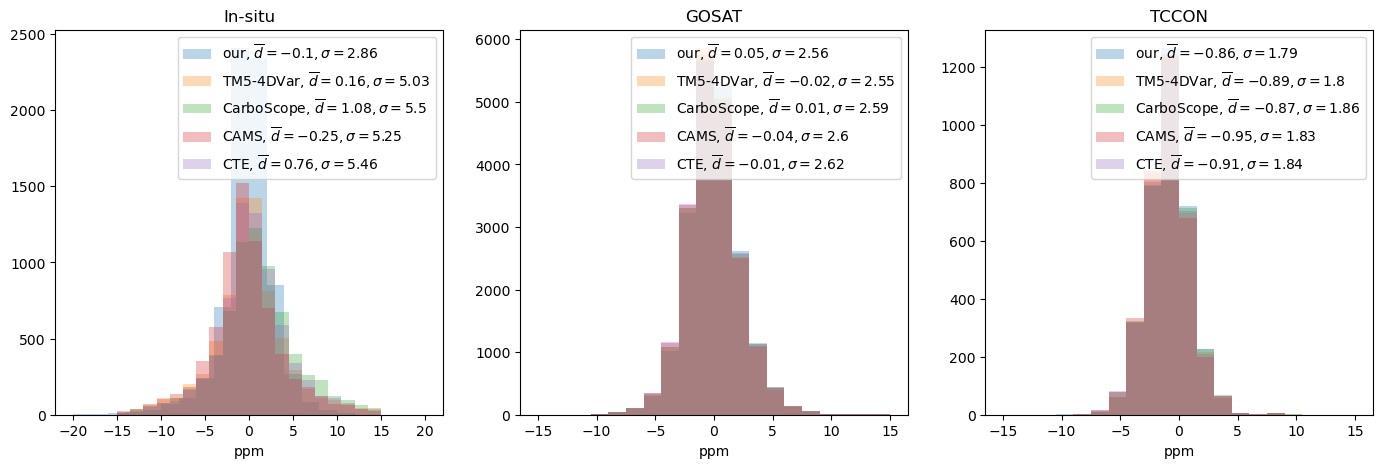

NISMON-CO2
insitu: , $\overline{d}=-0.41, \sigma=5.73$
GOSAT: , $\overline{d}=-0.13, \sigma=2.62$
TCCON: , $\overline{d}=-1.02, \sigma=1.88$
CT-NOAA
insitu: , $\overline{d}=0.29, \sigma=4.78$
GOSAT: , $\overline{d}=-0.19, \sigma=2.64$
TCCON: , $\overline{d}=-1.03, \sigma=1.9$
CMS-Flux
insitu: , $\overline{d}=-0.68, \sigma=4.63$
GOSAT: , $\overline{d}=-0.15, \sigma=2.6$
TCCON: , $\overline{d}=-1.01, \sigma=1.89$
CAMS-Satellite
insitu: , $\overline{d}=0.28, \sigma=5.64$
GOSAT: , $\overline{d}=-0.07, \sigma=2.56$
TCCON: , $\overline{d}=-0.91, \sigma=1.81$
GONGGA
insitu: , $\overline{d}=0.44, \sigma=5.06$
GOSAT: , $\overline{d}=-0.11, \sigma=2.6$
TCCON: , $\overline{d}=-0.95, \sigma=1.89$


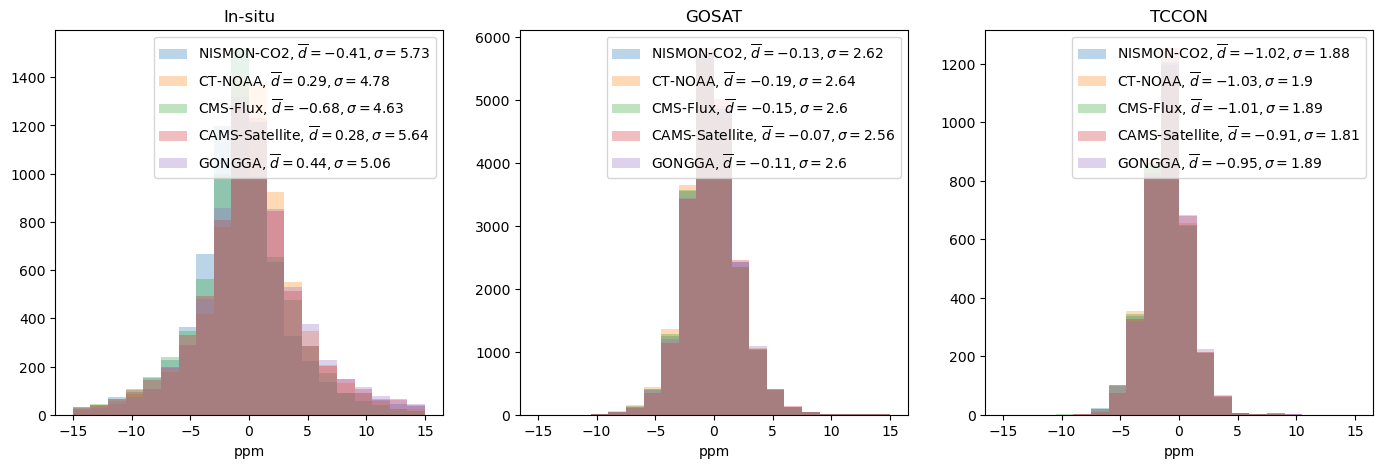

COLA
insitu: , $\overline{d}=0.01, \sigma=4.67$
GOSAT: , $\overline{d}=-0.05, \sigma=2.6$
TCCON: , $\overline{d}=-0.94, \sigma=1.86$
GCASv2
insitu: , $\overline{d}=0.64, \sigma=5.67$
GOSAT: , $\overline{d}=-0.07, \sigma=2.59$
TCCON: , $\overline{d}=-0.92, \sigma=1.86$
UoE
insitu: , $\overline{d}=0.39, \sigma=5.06$
GOSAT: , $\overline{d}=0.03, \sigma=2.6$
TCCON: , $\overline{d}=-0.87, \sigma=1.83$
IAPCAS
insitu: , $\overline{d}=-0.26, \sigma=4.73$
GOSAT: , $\overline{d}=0.01, \sigma=2.61$
TCCON: , $\overline{d}=-0.91, \sigma=1.85$
MIROC
insitu: , $\overline{d}=-0.29, \sigma=5.07$
GOSAT: , $\overline{d}=-0.24, \sigma=2.61$
TCCON: , $\overline{d}=-1.06, \sigma=1.9$


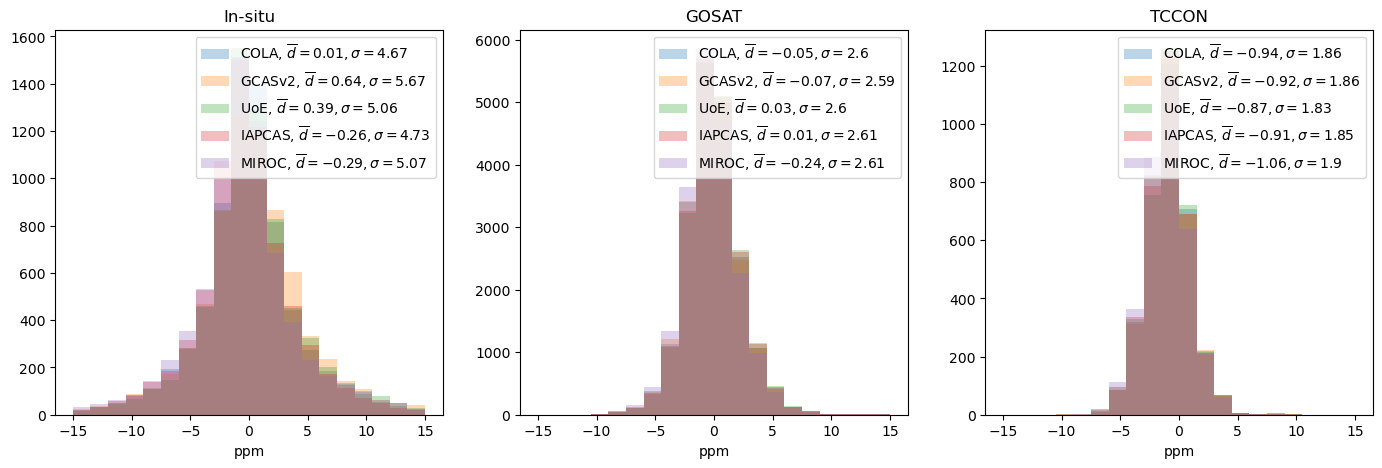

NTFVAR
insitu: , $\overline{d}=0.38, \sigma=5.64$
GOSAT: , $\overline{d}=-0.08, \sigma=2.6$
TCCON: , $\overline{d}=-0.96, \sigma=1.85$


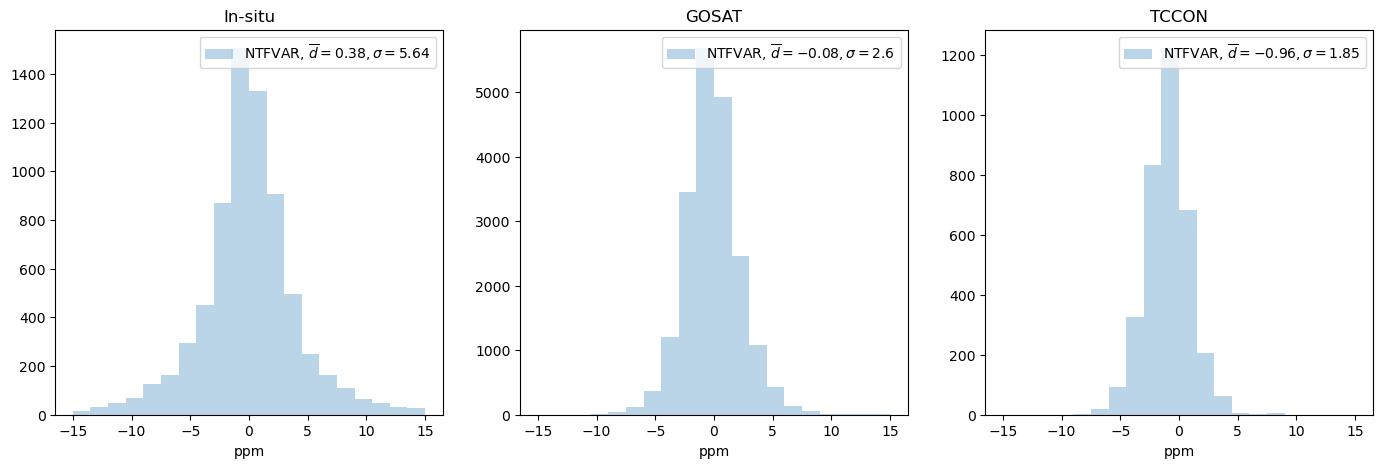

In [20]:
nbins=20
max_min=(-20,20)
fig,axs=plt.subplots(1,3,figsize=(17,5))

title=['In-situ', 'GOSAT','TCCON']
vars=['posterior_diff','ref_RemoteC_IS_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
model=['our','TM5-4DVar']
for name in gcp_names:
    vars.append(f'ref_{name}_diff')
    model.append(name)
s=0
for k,var in enumerate(vars):
    print(model[k])
    temp=inversion.insitu[var]
    d0=np.round(np.mean(temp).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
    d_std=np.round(np.std(temp).compute().item(),2)
    label=fr'{model[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs[0].hist(temp,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[0].legend()
    axs[0].set_xlabel('ppm')
    axs[0].set_title(title[0])

    max_min=(-15,15)
    temp=inversion.gosat[var]
    d0=np.round(np.mean(temp).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
    d_std=np.round(np.std(temp).compute().item(),2)
    label=fr'{model[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'GOSAT: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs[1].hist(temp,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[1].legend()
    axs[1].set_xlabel('ppm')
    axs[1].set_title(title[1])

    
    max_min=(-15,15)
    temp=inversion.tccon[var]
    d0=np.round(np.mean(temp).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
    d_std=np.round(np.std(temp).compute().item(),2)
    label=fr'{model[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'TCCON: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs[2].hist(temp,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[2].legend()
    axs[2].set_xlabel('ppm')
    axs[2].set_title(title[2])
    s+=1
    if s==5:
        s=0
        plt.show()
        fig,axs=plt.subplots(1,3,figsize=(17,5))

plt.show()
#plt.savefig(f'{savefig}/histogramm_diff_diurnal.png')